# Beating the baseline; the vendor curve tested; the good-enough call and the forecast note: when does a forecast earn trust, and what do you send?

**Week 4, Friday, concept notebook 4 of 4, beside chapter 4 of the deck.** The chai stall is invented: it sits at a hostel gate, and every cup in this notebook is an invented number written by the day's seeded generator. Notebook
03 fixed how a rule is scored: on hidden days, in cups and in rupees.

**Who needs the answer.** The stall's owner (invented), offered a "model" by a nephew with a
laptop, and Flipkart's regional operations head, offered a vendor's curve that fits history
within 2 percent.

**The questions on the way.** What does a perfect fit say about tomorrow? Does the clever
rule beat the baseline? Is a better forecast worth having? What goes to the milkman?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# fourteen days of the invented stall, Monday 3 to Sunday 16 March 2025; the last seven are hidden
days = pd.read_csv("../data/C2_W04_D05_chai_stall_nephew_STUDENT.csv")
can = 40                          # cups of tea one milk can makes (invented)
unsold_rs, short_rs = 6, 12       # Rs a cup unsold, Rs a cup short (invented)
check("fourteen days, the last seven hidden", len(days) == 14 and days.hidden.sum() == 7)
days                              # every number invented

PASS fourteen days, the last seven hidden


,date,weekday,cups,hidden
0,2025-03-03,Mon,100,0
1,2025-03-04,Tue,104,0
2,2025-03-05,Wed,98,0
3,2025-03-06,Thu,110,0
4,2025-03-07,Fri,102,0
5,2025-03-08,Sat,106,0
6,2025-03-09,Sun,63,0
7,2025-03-10,Mon,103,1
8,2025-03-11,Tue,104,1
9,2025-03-12,Wed,104,1


## What does a perfect fit say about tomorrow?

**Fit** is how close a rule sits to the days it was built on; **forecast error** is how far
it misses days it never saw. The nephew's first offer is a curve through the first four
days, 100, 104, 98 and 110 cups, which passes through every one of them exactly.

**Predict before you run.** Which forecast for day 5 lands closest?

a) The straight line: the best line through the four days, about 109
b) The exact curve: it passes through all four days exactly
c) Naive: repeat the last day, 110
d) They land within five cups of each other

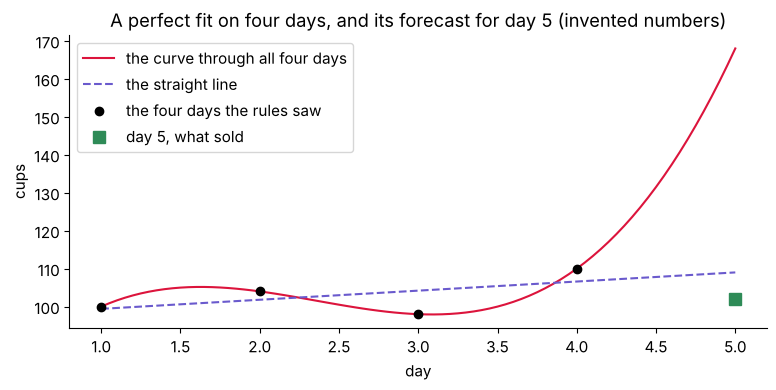

the line: slope 2.4, value at day 0 97, 3.1 cups from the four days on average; day 5: 109
the curve: 0 cups from the four days; day 5: 168
day 5 sold 102: the line misses by 7, the curve by 66, naive by 8
PASS by hand and by code, the curve says 168
PASS the curve fits the four days exactly
PASS its forecast misses day 5 by more than 50
PASS the line, which fits worse, misses by less than 10


In [2]:
four, day5 = days.cups.iloc[:4].tolist(), days.cups.iloc[4]
x = [1, 2, 3, 4]

def line_through(values):
    """The least-squares straight line through the days: its slope and its value at day 0."""
    xm, ym = sum(x) / len(x), sum(values) / len(values)
    slope = sum((a - xm) * (b - ym) for a, b in zip(x, values)) / sum((a - xm) ** 2 for a in x)
    return slope, ym - slope * xm

def curve_at(t, values):
    """The one curve that passes through every day exactly, read at day t."""
    total = 0
    for i, v in zip(x, values):
        term = v
        for j in x:
            if j != i:
                term *= (t - j) / (i - j)
        total += term
    return total

slope, start = line_through(four)
line5, curve5 = start + slope * 5, curve_at(5, four)
line_fit = sum(abs(start + slope * a - b) for a, b in zip(x, four)) / len(x)
curve_fit = sum(abs(curve_at(a, four) - b) for a, b in zip(x, four)) / len(x)
grid = [1 + k / 20 for k in range(81)]                       # day 1 to day 5 in small steps
fig, ax = plt.subplots()
ax.plot(grid, [curve_at(t, four) for t in grid], color="crimson", label="the curve through all four days")
ax.plot([1, 5], [start + slope, line5], color="slateblue", ls="--", label="the straight line")
ax.plot(x, four, "o", color="black", label="the four days the rules saw")
ax.plot(5, day5, "s", color="seagreen", markersize=9, label="day 5, what sold")
ax.set_xlabel("day")
ax.set_ylabel("cups")
ax.set_title("A perfect fit on four days, and its forecast for day 5 (invented numbers)")
ax.legend()
plt.show()
print(f"the line: slope {slope:.1f}, value at day 0 {start:.0f}, {line_fit:.1f} cups from the four days on average; day 5: {line5:.0f}")
print(f"the curve: {curve_fit:.0f} cups from the four days; day 5: {curve5:.0f}")
print(f"day 5 sold {day5}: the line misses by {abs(line5 - day5):.0f}, the curve by {abs(curve5 - day5):.0f}, naive by {abs(four[-1] - day5)}")
check("by hand and by code, the curve says 168", round(curve5) == 110 + 12 + 18 + 28)
check("the curve fits the four days exactly", curve_fit < 1e-9)
check("its forecast misses day 5 by more than 50", abs(curve5 - day5) > 50)
check("the line, which fits worse, misses by less than 10", abs(line5 - day5) < 10)

**What happened.** The answer is a, with naive a cup behind. Day 5 sold 102. The curve
through all four days fits them perfectly, with an error of 0, and said 168: a miss of 66,
the worst in the room. The straight line sits about 3.1 cups from the four days on average,
said 109 and missed by 7; naive said 110 and missed by 8. The curve's 168 needs no algebra:
the four days' differences are 4, -6 and 12, their differences -10 and 18, and theirs 28;
carry each last difference down and the curve climbs to 110 + 12 + 18 + 28 = 168. An
interviewer calls fit in-sample and forecast error out-of-sample: "A model which fits the
training data well will not necessarily forecast well" (Forecasting: Principles and
Practice, section 5.8, checked 13 October 2026).

## Does the clever rule beat the baseline?

The nephew's second offer is the mean of the last seven days, 97.6 cups every day. Score
it against the seasonal naive, the same day last week, on the seven hidden days, 10 to 16
March, by the measure notebook 03 fixed.

**Predict before you run.** Which rule scores the lower MAE on the hidden days, and by how
much?

the nephew's mean: MAE 12.4 cups, lean -2.6
seasonal naive: MAE 4.0 cups, lean -2.6


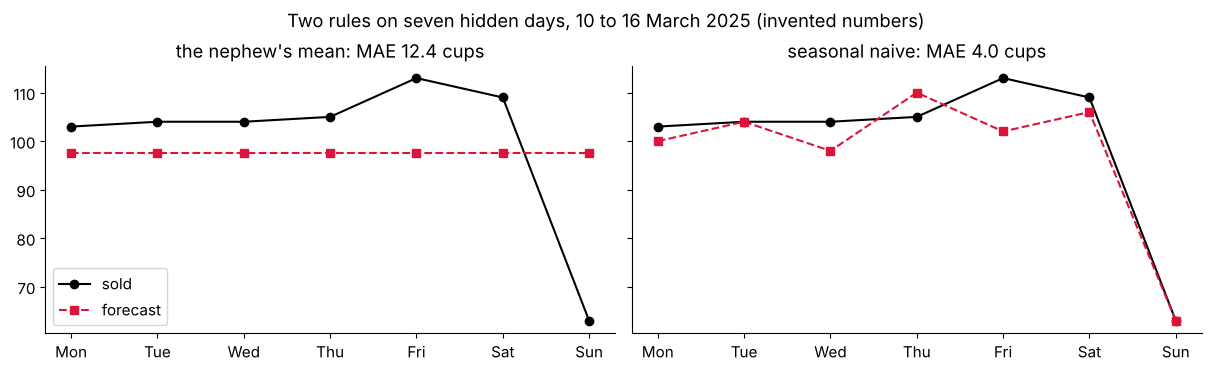

the mean's miss on the hidden Sunday: +34.6 cups
PASS the seasonal naive wins on the hidden days
PASS the nephew's mean earns no place


In [3]:
seen, hidden = days.cups.iloc[:7].tolist(), days.cups.iloc[7:].tolist()     # 3 to 9 March, and 10 to 16 March
mean_rule = sum(seen) / 7
rules = {"the nephew's mean": [mean_rule] * 7, "seasonal naive": seen}       # hidden day k copies seen day k
scores = {}
for name, f in rules.items():
    misses = [a - b for a, b in zip(f, hidden)]
    scores[name] = sum(abs(m) for m in misses) / 7
    print(f"{name}: MAE {scores[name]:.1f} cups, lean {sum(misses) / 7:+.1f}")

def earns_a_place(rule_mae, baseline_mae):
    """The chapter's rule: nothing goes to the order unless it beats the seasonal naive on hidden days."""
    return rule_mae < baseline_mae

labels = days.weekday.iloc[7:].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, constrained_layout=True)
for ax, (name, f) in zip(axes, rules.items()):
    ax.plot(labels, hidden, color="black", marker="o", label="sold")
    ax.plot(labels, f, color="crimson", ls="--", marker="s", label="forecast")
    ax.set_title(f"{name}: MAE {scores[name]:.1f} cups")
axes[0].legend()
fig.suptitle("Two rules on seven hidden days, 10 to 16 March 2025 (invented numbers)")
plt.show()
print(f"the mean's miss on the hidden Sunday: {mean_rule - hidden[-1]:+.1f} cups")
check("the seasonal naive wins on the hidden days", scores["seasonal naive"] < scores["the nephew's mean"])
check("the nephew's mean earns no place", not earns_a_place(scores["the nephew's mean"], scores["seasonal naive"]))

**What happened.** The seasonal naive misses by 4.0 cups a day and the nephew's mean by
12.4: the mean ignores the Sunday dip and misses that Sunday by 34.6 cups. Both lean low by
the same 2.6 cups, so here the lean cannot separate them and the size does. Named last:
nothing goes to the order unless it beats the seasonal naive on hidden days, by the
measure fixed before either rule ran.

## Is a better forecast worth having?

Milk comes in cans of 40 cups (invented), so the owner orders whole cans: the forecast over
40, rounded up.

**Predict before you run.** A forecast that knew the future exactly would beat the
seasonal naive's 4.0 cups a day. On how many of the seven hidden days would it order a
different number of cans?

                  Mon  Tue  Wed  Thu  Fri  Sat  Sun
seasonal naive      3    3    3    3    3    3    2
perfect forecast    3    3    3    3    3    3    2
nephew's mean       3    3    3    3    3    3    3
days that order differently from a perfect forecast: {'seasonal naive': 0, 'perfect forecast': 0, "nephew's mean": 1}


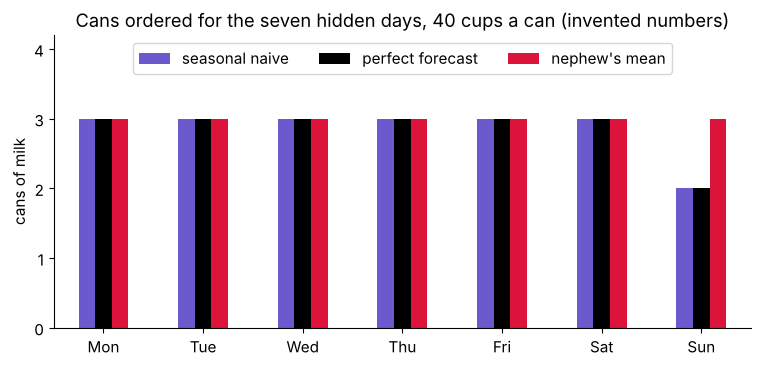

PASS the seasonal naive orders a perfect forecast's cans on all seven days
PASS the nephew's mean orders a third can on the Sunday


In [4]:
def cans(cups):
    return math.ceil(cups / can)                         # whole cans, rounded up

order = pd.DataFrame({"seasonal naive": [cans(v) for v in seen],
                      "perfect forecast": [cans(v) for v in hidden],
                      "nephew's mean": [cans(mean_rule)] * 7}, index=labels)
print(order.T.to_string())
differ = {name: int((order[name] != order["perfect forecast"]).sum()) for name in order}
print("days that order differently from a perfect forecast:", differ)
ax = order.plot.bar(color=["slateblue", "black", "crimson"], rot=0)
ax.set_ylim(0, 4.2)
ax.set_yticks(range(5))
ax.legend(ncol=3, loc="upper center")
ax.set_ylabel("cans of milk")
ax.set_title("Cans ordered for the seven hidden days, 40 cups a can (invented numbers)")
plt.show()
check("the seasonal naive orders a perfect forecast's cans on all seven days", differ["seasonal naive"] == 0)
check("the nephew's mean orders a third can on the Sunday", differ["nephew's mean"] == 1 and order["nephew's mean"].iloc[-1] == 3)

**What happened.** On none: the seasonal naive orders 3 cans a weekday and 2 on Sunday,
exactly what a forecast that knew the future would order, on all seven days. The nephew's
mean orders a third can on Sunday, milk that sours. Named last: **good enough** is a claim
about the decision, never about the model. A better forecast is worth having only if it
would change what gets ordered, so the owner stops improving here.

## What goes to the milkman?

The **forecast note** carries four lines: the number, the method (what it copies), the
error bar (the MAE on hidden days, in the unit and in rupees, each direction priced) and
what would make it wrong. The cell below prints it from the notebook's own variables, so
every number in it is one the notebook computed.

In [5]:
bar = scores["seasonal naive"]
note = [
    f"The number: {order['seasonal naive'].iloc[0]} cans a day Monday to Saturday, {order['seasonal naive'].iloc[-1]} on Sunday.",
    "The method: the same day last week, the seasonal naive, which beat the nephew's mean on seven hidden days.",
    f"The error bar: {bar:.1f} cups a day on those days, about Rs {bar * unsold_rs:.0f} a day if it runs high "
    f"and Rs {bar * short_rs:.0f} if it runs short.",
    "What would make it wrong: exams starting early, or the hostel emptying for a holiday.",
]
print("\n".join(note))
check("the note holds four lines", len(note) == 4)
check("the error bar is in cups and in rupees", "cups" in note[2] and "Rs" in note[2])

The number: 3 cans a day Monday to Saturday, 2 on Sunday.
The method: the same day last week, the seasonal naive, which beat the nephew's mean on seven hidden days.
The error bar: 4.0 cups a day on those days, about Rs 24 a day if it runs high and Rs 48 if it runs short.
What would make it wrong: exams starting early, or the hostel emptying for a holiday.
PASS the note holds four lines
PASS the error bar is in cups and in rupees


**The plausible wrong answer.** "The model fits 100 percent of history; order for 168
cups." **The decision it misleads:** 168 cups is 5 cans against the 3 that day 5 needed,
two cans of milk that sour. **The check:** the score on hidden days. **The fix:** the
baseline's number with its error bar.

**Your turn.** Price the nephew's Sunday. Its mean orders one can more than a perfect
forecast on Sunday; a can makes 40 cups, and a cup unsold wastes Rs 6 of milk (invented).
Fill the blanks, type the lines into the empty cell below and run them; the check prints
PASS when the price is right.

```python
extra = order["nephew's mean"].iloc[-1] - order["perfect forecast"].iloc[-1]   # cans beyond the need
waste_rs = extra * ___ * ___
check("the nephew's Sunday wastes Rs 240 of milk", waste_rs == 240)
```

## Which rules does the chapter leave?

1. Fit is measured on the days a rule was built on, and it proves nothing about tomorrow.
2. Nothing goes to the order unless it beats the seasonal naive on hidden days, by the
   measure fixed first.
3. Good enough is a claim about the decision: stop improving when a better forecast would
   order the same.
4. The note carries the number, the method, the error bar in the unit and in rupees, and
   what would make it wrong.

**In the interview.** [F] "What baseline must any forecast beat, and why?" [F] "A vendor
promises 22 percent growth; how do you test the claim?" Each is answered with the hidden
periods and the seasonal naive, never with the fit.

In [6]:
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
print(vendor.kind.value_counts().to_string())                  # the vendor's fits, hidden-week forecasts, weeks ahead
aligned_mae, bot_mae, vendor_mae = 6615, 9831, 16400           # notebook 06's scoreboard, shipments a week
per_shift = 120                                                # shipments a packer packs in a shift
print(f"against festival-aligned, the house bot misses by {(bot_mae - aligned_mae) / per_shift:.0f} more shifts "
      f"a week and the vendor by {(vendor_mae - aligned_mae) / per_shift:.0f}")
check("the vendor's file labels fits, hidden-week forecasts and the weeks ahead",
      set(vendor.kind) == {"fitted", "holdout", "forecast"})
check("a rule better by 100 shipments a week gains less than one shift", 100 < per_shift)

kind
fitted      91
holdout     13
forecast    10
against festival-aligned, the house bot misses by 27 more shifts a week and the vendor by 82
PASS the vendor's file labels fits, hidden-week forecasts and the weeks ahead
PASS a rule better by 100 shipments a week gains less than one shift


## What did the chapter answer?

| Question | The stall's answer, in invented numbers |
|---|---|
| What does a perfect fit say about tomorrow? | Nothing: the curve fits with an error of 0 and misses day 5 by 66 |
| Does the clever rule beat the baseline? | No: the nephew's mean scores 12.4 cups against the seasonal naive's 4.0 |
| Is a better forecast worth having? | Not here: the seasonal naive orders the cans a perfect forecast would |
| What goes to the milkman? | 3 cans a weekday and 2 on Sunday, from last week's same day, give or take 4.0 cups, Rs 24 to Rs 48 a day |

At Flipkart the vendor's curve fits its 91 weeks within 1.4 percent and misses the thirteen
hidden weeks by 16,400 a week. The decision unit is a shift of 120 shipments, so the house
bot's gap is 27 shifts a week and the vendor's 82. Chapter 6's notebook,
`C2_W04_D05_06_case_holdout_scoreboard_STUDENT.ipynb`, tests the vendor's curve, and
chapter 7's, `C2_W04_D05_07_case_good_enough_forecast_note_STUDENT.ipynb`, makes the
good-enough call and books the plan.